# Modul 6: CNN Lanjutan dan Transfer Learning

**Nama:** ISI NAMA  
**NIM:** ISI NIM  
**Kelas:** ISI KELAS  
**Tanggal:** YYYY-MM-DD  
**Sumber dataset:** ISI (nama dataset dan asalnya)

Simpan berkas ini sebagai `M06_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | Pre-lab, B–F | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | G–H | Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Hanya itu isian pada bagian terbimbing.
2. Siapkan data lebih dahulu dengan menekan **Siapkan dataset di laptop** di halaman modul. Data transfer 4 kelas × 120 citra masuk ke `data/raw/transfer/` dan bobot `ResNet18_Weights.IMAGENET1K_V1` ke `data/raw/torch/`. Tidak ada sel yang mengunduh data atau bobot.
3. Tekan **Restart**, lalu **Run all**. Seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`. Bagian E dan F melatih lima model ResNet18 di CPU sehingga memerlukan waktu beberapa menit per run; log epoch tampil bertahap.
4. Keluaran yang tidak bergantung pada NIM, yaitu isi transformasi, ukuran split, jumlah parameter, dan bukti pembekuan, harus sama persis dengan naskah. Angka hasil training bergantung pada seed NIM Anda.
5. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO`. Transformasi tetap berasal dari `weights.transforms()`, augmentasi hanya melekat pada split latih, dan test set dipakai **satu kali** pada bagian G.
6. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat. Pertahankan semua hasil eksperimen, termasuk yang tidak sesuai hipotesis.

In [ ]:
import copy
import platform
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from torchvision.models import ResNet18_Weights, resnet18

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = 'ISI_NIM'  # Ganti dengan NIM lengkap Anda, misalnya '120140167'.
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
SEED = int(NIM[-4:])  # seed individual: empat digit terakhir NIM
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
environment = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'torch': torch.__version__,
    'device': str(DEVICE),
    'seed': SEED,
}
environment

## A. Pre-lab · Terbimbing

1. **Mengapa normalisasi harus sama dengan saat pralatih:** Bobot awal belajar dari masukan pada skala/distribusi kanal tertentu. Mengubah normalisasi menggeser distribusi aktivasi sejak layer pertama sehingga fitur pralatih dan statistik BatchNorm tidak lagi menerima data seperti yang diharapkan.
2. **Gradien dan waktu komputasi layer beku:** Parameter dengan `requires_grad=False` tidak memperoleh tensor `.grad` dan autograd tidak menghitung turunan terhadap parameter itu. Forward pass tetap dilakukan, tetapi penyimpanan aktivasi/backward untuk bagian beku berkurang sehingga memori dan waktu training biasanya lebih kecil.
3. **Parameter `Linear(512,5)`:** $512\times5+5=2\,565$ parameter, terdiri atas 2.560 bobot dan 5 bias.
4. **Mengapa LR fine-tuning lebih kecil:** Bobot pralatih sudah berada pada representasi yang berguna; langkah besar dapat merusaknya (*catastrophic forgetting*). Learning rate kecil menyesuaikan fitur secara bertahap, sedangkan model acak perlu bergerak lebih jauh dari inisialisasinya.

## B. Bobot pralatih dan praproses · Terbimbing

Ambil transformasi dari objek bobot, lalu bangun augmentasi yang memakai normalisasi **yang sama**.

In [2]:
bobot = ResNet18_Weights.IMAGENET1K_V1
tf_eval = bobot.transforms()
print(tf_eval)
MEAN = tuple(tf_eval.mean)
STD = tuple(tf_eval.std)
SISI = int(tf_eval.crop_size[0])

tf_aug = T.Compose([
    T.RandomResizedCrop(SISI, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD),
])

print('crop:', SISI, '| mean:', MEAN, '| std:', STD)
assert list(MEAN) == [0.485, 0.456, 0.406], 'MEAN harus berasal dari bobot pralatih'
assert list(STD) == [0.229, 0.224, 0.225]

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
crop: 224 | mean: (0.485, 0.456, 0.406) | std: (0.229, 0.224, 0.225)


In [3]:
ROOT = Path('../../data/raw/transfer')
if not ROOT.exists():
    ROOT = Path('data/raw/transfer')

ds_aug = ImageFolder(ROOT, transform=tf_aug)
ds_polos = ImageFolder(ROOT, transform=tf_eval)
KELAS = ds_polos.classes
y = np.array(ds_polos.targets)
all_indices = np.arange(len(y))

idx_latih, idx_sisa = train_test_split(
    all_indices,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)
idx_val, idx_uji = train_test_split(
    idx_sisa,
    test_size=0.50,
    stratify=y[idx_sisa],
    random_state=SEED,
)

ds_latih = Subset(ds_aug, idx_latih)
# Versi polos hanya untuk menghitung metrik train yang sebanding dengan validation.
ds_latih_polos = Subset(ds_polos, idx_latih)
ds_val = Subset(ds_polos, idx_val)
ds_uji = Subset(ds_polos, idx_uji)

print(f'kelas ({len(KELAS)}): {KELAS}')
print(f'latih {len(ds_latih)}  validasi {len(ds_val)}  uji {len(ds_uji)}')
print('citra per kelas:', np.bincount(y).tolist())
print('distribusi train/val/test:',
      np.bincount(y[idx_latih]).tolist(),
      np.bincount(y[idx_val]).tolist(),
      np.bincount(y[idx_uji]).tolist())

assert len(KELAS) >= 4, 'dataset harus punya minimal empat kelas'
assert np.bincount(y).min() >= 120, 'setiap kelas minimal 120 citra'
assert (len(ds_latih), len(ds_val), len(ds_uji)) == (336, 72, 72)
assert ds_val.dataset is ds_polos and ds_uji.dataset is ds_polos
assert ds_latih.dataset is ds_aug
print('dataset dan split sesuai protokol')

kelas (4): ['coat', 'pullover', 'shirt', 't_shirt_top']
latih 336  validasi 72  uji 72
citra per kelas: [120, 120, 120, 120]
distribusi train/val/test: [84, 84, 84, 84] [18, 18, 18, 18] [18, 18, 18, 18]
dataset dan split sesuai protokol


In [ ]:
# Satu batch latih persis seperti yang akan dilihat model (sudah melalui tf_aug).
g_contoh = torch.Generator().manual_seed(SEED)
xb_contoh, yb_contoh = next(iter(DataLoader(ds_latih, batch_size=8, shuffle=True, generator=g_contoh)))
print('shape batch  :', tuple(xb_contoh.shape), xb_contoh.dtype)
print(f'rentang nilai: {xb_contoh.min().item():.3f} s.d. {xb_contoh.max().item():.3f} (sesudah Normalize)')
print('label        :', [KELAS[i] for i in yb_contoh.tolist()])

# Normalize dibalik hanya untuk ditampilkan: x * std + mean.
mean_tensor = torch.tensor(MEAN).view(3, 1, 1)
std_tensor = torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.8), constrained_layout=True)
for ax, image, label in zip(axes.flat, xb_contoh, yb_contoh):
    ax.imshow((image * std_tensor + mean_tensor).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(KELAS[int(label)])
    ax.axis('off')
fig.suptitle('Satu Batch Latih setelah tf_aug (normalisasi dibalik untuk tampilan)', fontsize=13)
plt.show()

## C. Head baru dan hitungan parameter · Terbimbing

In [4]:
K = len(KELAS)

def buat_model(pralatih=True):
    seed_everything(SEED)
    weights = bobot if pralatih else None
    model = resnet18(weights=weights)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, K)
    return model.to(DEVICE)

model = buat_model()
total = sum(parameter.numel() for parameter in model.parameters())
head = sum(parameter.numel() for parameter in model.fc.parameters())
layer4 = sum(parameter.numel() for parameter in model.layer4.parameters())

print(f'total          : {total:,}')
print(f'head           : {head:,}  ({100*head/total:.3f}%)')
print(f'layer4 + head  : {layer4 + head:,}  ({100*(layer4+head)/total:.1f}%)')
assert head == 512 * K + K, 'dimensi head belum sesuai jumlah kelas'

total          : 11,178,564
head           : 2,052  (0.018%)
layer4 + head  : 8,395,780  (75.1%)


## D. Membekukan dan membuktikannya · Terbimbing

Dua bukti wajib: status `requires_grad`, **dan** bobot beku yang tidak bergerak setelah satu update.

In [6]:
def bekukan(model, strategi):
    strategi = strategi.strip().lower()
    if strategi not in {'frozen', 'partial', 'full', 'scratch'}:
        raise ValueError("strategi harus 'frozen', 'partial', 'full', atau 'scratch'")

    for parameter in model.parameters():
        parameter.requires_grad = False

    if strategi == 'frozen':
        for parameter in model.fc.parameters():
            parameter.requires_grad = True
    elif strategi == 'partial':
        for parameter in model.layer4.parameters():
            parameter.requires_grad = True
        for parameter in model.fc.parameters():
            parameter.requires_grad = True
    else:  # full dan scratch
        for parameter in model.parameters():
            parameter.requires_grad = True
    return model

def n_terlatih(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

trainable_by_strategy = {}
for strategi in ('frozen', 'partial', 'full'):
    current = bekukan(buat_model(), strategi)
    trainable_by_strategy[strategi] = n_terlatih(current)
    print(f'{strategi:>8}: {n_terlatih(current):>11,} ({100*n_terlatih(current)/total:5.1f}%)')

m_cek = bekukan(buat_model(), 'frozen')
assert n_terlatih(m_cek) == head, 'strategi frozen harus melatih head saja'
assert all(not parameter.requires_grad for parameter in m_cek.layer1.parameters())
assert all(parameter.requires_grad for parameter in m_cek.fc.parameters())

  frozen:       2,052 (  0.0%)


 partial:   8,395,780 ( 75.1%)


    full:  11,178,564 (100.0%)


In [7]:
salinan = m_cek.layer1[0].conv1.weight.detach().clone()
head_before = m_cek.fc.weight.detach().clone()
optimizer_check = torch.optim.Adam(
    [parameter for parameter in m_cek.parameters() if parameter.requires_grad],
    lr=1e-3,
)
criterion_check = nn.CrossEntropyLoss()
check_loader = DataLoader(ds_latih, batch_size=8, shuffle=False)
xb_check, yb_check = next(iter(check_loader))
xb_check, yb_check = xb_check.to(DEVICE), yb_check.to(DEVICE)

m_cek.eval()  # Backbone dan BatchNorm tetap; head Linear tetap dapat belajar.
optimizer_check.zero_grad()
loss_check = criterion_check(m_cek(xb_check), yb_check)
loss_check.backward()
optimizer_check.step()

selisih = (m_cek.layer1[0].conv1.weight.detach() - salinan).abs().max().item()
head_change = (m_cek.fc.weight.detach() - head_before).abs().max().item()
print(f'selisih maksimum bobot beku: {selisih:.2e}')
print(f'perubahan maksimum head     : {head_change:.2e}')
assert selisih == 0.0, 'bobot beku ternyata berubah — periksa isi optimizer'
assert head_change > 0.0, 'head seharusnya berubah setelah update'
print('pembekuan terbukti dengan status gradien dan update nyata')

selisih maksimum bobot beku: 0.00e+00
perubahan maksimum head     : 1.00e-03
pembekuan terbukti dengan status gradien dan update nyata


In [ ]:
# Strategi partial: hanya layer4 dan head yang boleh berubah setelah satu update.
m_partial = bekukan(buat_model(), 'partial')
sebelum = {nama: parameter.detach().clone() for nama, parameter in m_partial.named_parameters()}
optimizer_partial = torch.optim.Adam(
    [parameter for parameter in m_partial.parameters() if parameter.requires_grad],
    lr=1e-4,
)
m_partial.eval()           # BatchNorm blok beku memakai running statistics pralatih.
m_partial.layer4.train()
m_partial.fc.train()
optimizer_partial.zero_grad()
criterion_check(m_partial(xb_check), yb_check).backward()
optimizer_partial.step()

baris = []
for blok in ('conv1', 'bn1', 'layer1', 'layer2', 'layer3', 'layer4', 'fc'):
    anggota = [(nama, p) for nama, p in m_partial.named_parameters() if nama.split('.')[0] == blok]
    perubahan = max((p.detach() - sebelum[nama]).abs().max().item() for nama, p in anggota)
    baris.append({
        'blok': blok,
        'parameter': sum(p.numel() for _, p in anggota),
        'requires_grad': all(p.requires_grad for _, p in anggota),
        'perubahan_maks': perubahan,
    })
bukti_partial = pd.DataFrame(baris)
print(bukti_partial.to_string(index=False, formatters={
    'parameter': '{:,}'.format, 'perubahan_maks': '{:.2e}'.format}))

beku = bukti_partial[~bukti_partial['blok'].isin(['layer4', 'fc'])]
assert (beku['perubahan_maks'] == 0.0).all() and not beku['requires_grad'].any(), 'blok beku ternyata berubah'
assert (bukti_partial.set_index('blok').loc[['layer4', 'fc'], 'perubahan_maks'] > 0).all()
assert bukti_partial.loc[bukti_partial['blok'].isin(['layer4', 'fc']), 'parameter'].sum() == layer4 + head
print('pembekuan partial terbukti: hanya layer4 dan fc yang bergerak')

### Mengapa dua bukti diperlukan?

`requires_grad=False` mencegah autograd membuat gradien baru, tetapi tidak otomatis menghapus gradien lama yang sudah tersimpan. Jika parameter dibekukan setelah pernah memperoleh `.grad` lalu tetap berada dalam optimizer—terutama optimizer yang memiliki momentum/weight decay—`step()` masih dapat mengubahnya memakai state/gradien lama. Bobot juga dapat berubah melalui operasi manual *in-place* atau pemuatan checkpoint; karena itu membandingkan salinan bobot sebelum/sesudah update membuktikan perilaku aktual, bukan hanya konfigurasi flag.

## E. Empat run terkendali · Terbimbing

Data, seed, batch, dan epoch sama. Yang berbeda hanya bobot awal dan bagian yang boleh berubah.

In [8]:
BATCH, EPOCH = 32, 5

def loader(ds, batch, acak):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak,
                      generator=generator if acak else None)

@torch.no_grad()
def evaluasi(model, ds):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss, correct = 0.0, 0
    for xb, yb in loader(ds, BATCH, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item()
        correct += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), correct / len(ds)

def aktifkan_mode_training(model, strategi):
    model.train()
    if strategi == 'frozen':
        # Cegah running statistics BatchNorm backbone berubah.
        model.eval()
        model.fc.train()
    elif strategi == 'partial':
        model.eval()
        model.layer4.train()
        model.fc.train()

def jalankan(strategi, lr, label, epoch=EPOCH, augmentasi='ringan'):
    model = buat_model(pralatih=strategi != 'scratch')
    model = bekukan(model, strategi)
    trainable_parameters = [
        parameter for parameter in model.parameters() if parameter.requires_grad
    ]
    optimizer = torch.optim.Adam(trainable_parameters, lr=lr)
    criterion = nn.CrossEntropyLoss()
    train_loader = loader(ds_latih, BATCH, True)
    history = {
        'epoch': [], 'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [], 'gap': [],
        'optimization_loss': [],
    }
    updates = 0
    start = time.perf_counter()

    for epoch_index in range(1, epoch + 1):
        aktifkan_mode_training(model, strategi)
        loss_sum, correct, seen = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(xb)
            correct += (logits.argmax(1) == yb).sum().item()
            seen += len(xb)
            updates += 1

        train_loss, train_acc = evaluasi(model, ds_latih_polos)
        val_loss, val_acc = evaluasi(model, ds_val)
        history['epoch'].append(epoch_index)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['gap'].append(val_loss - train_loss)
        history['optimization_loss'].append(loss_sum / seen)

    runtime = time.perf_counter() - start
    note = {
        'run_id': label,
        'seed': SEED,
        'strategi': strategi,
        'bobot_awal': 'random' if strategi == 'scratch' else 'ImageNet1K_V1',
        'learning_rate': lr,
        'parameter_total': sum(parameter.numel() for parameter in model.parameters()),
        'parameter_terlatih': n_terlatih(model),
        'augmentasi': augmentasi,
        'epochs': epoch,
        'n_update': updates,
        'train_loss': history['train_loss'][-1],
        'train_acc': history['train_acc'][-1],
        'val_loss': history['val_loss'][-1],
        'val_acc': history['val_acc'][-1],
        'gap': history['gap'][-1],
        'detik_per_epoch': runtime / epoch,
        'runtime_s': runtime,
        'status': 'ok',
    }
    return model, history, note

hasil, kurva, model_simpan = [], {}, {}
initial_runs = [
    ('scratch', 1e-3, 'from-scratch'),
    ('frozen', 1e-3, 'frozen-backbone'),
    ('partial', 1e-4, 'partial-layer4'),
    ('full', 1e-4, 'full-finetune'),
]
for strategi, lr, label in initial_runs:
    current_model, history, note = jalankan(strategi, lr, label)
    hasil.append(note)
    kurva[label] = history
    model_simpan[label] = current_model
    print(f"{label}: val_loss={note['val_loss']:.4f}, val_acc={note['val_acc']:.4f}, "
          f"trainable={note['parameter_terlatih']:,}, {note['detik_per_epoch']:.2f}s/epoch")

df_strategi = pd.DataFrame(hasil)
display(df_strategi[['run_id', 'bobot_awal', 'parameter_terlatih', 'n_update',
                      'val_loss', 'val_acc', 'gap', 'detik_per_epoch']])
assert len(hasil) == 4, 'harus ada empat run strategi'
assert set(df_strategi['n_update']) == {55}

from-scratch: val_loss=2.1881, val_acc=0.3472, trainable=11,178,564, 21.58s/epoch


frozen-backbone: val_loss=0.8215, val_acc=0.7222, trainable=2,052, 24.19s/epoch


partial-layer4: val_loss=0.6127, val_acc=0.8194, trainable=8,395,780, 18.09s/epoch


full-finetune: val_loss=0.6815, val_acc=0.7917, trainable=11,178,564, 28.56s/epoch


,run_id,bobot_awal,parameter_terlatih,n_update,val_loss,val_acc,gap,detik_per_epoch
0,from-scratch,random,11178564,55,2.1881,0.3472,-0.2144,21.5754
1,frozen-backbone,ImageNet1K_V1,2052,55,0.8215,0.7222,0.0298,24.1872
2,partial-layer4,ImageNet1K_V1,8395780,55,0.6127,0.8194,0.4837,18.0886
3,full-finetune,ImageNet1K_V1,11178564,55,0.6815,0.7917,0.4366,28.5561


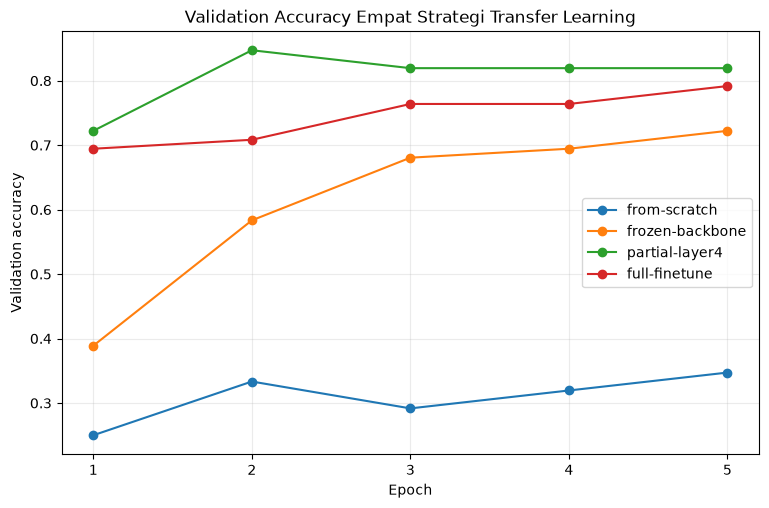

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for label, history in kurva.items():
    ax.plot(history['epoch'], history['val_acc'], marker='o', label=label)
ax.set(title='Validation Accuracy Empat Strategi Transfer Learning',
       xlabel='Epoch', ylabel='Validation accuracy')
ax.set_xticks(range(1, EPOCH + 1))
ax.grid(alpha=0.25)
ax.legend()
plt.show()

**Checkpoint menit ke-80.** Tunjukkan kepada asisten: parameter terlatih ketiga strategi, transformasi yang berasal dari objek bobot, dan selisih nol pada bobot beku.

## F. Augmentasi dan analisis kesalahan · Terbimbing

Augmentasi ringan (`RandomResizedCrop` skala 0,8–1,0 dan `RandomHorizontalFlip`) sudah dipakai keempat run bagian E. Strategi terbaik menurut validation loss dijalankan sekali lagi **tanpa augmentasi** dengan anggaran yang sama. Confusion matrix dan lima prediksi salah dihitung pada validation set; test set tetap untuk bagian G.

In [ ]:
best_initial = df_strategi.sort_values('val_loss').iloc[0]
best_strategy = str(best_initial['strategi'])
best_lr = float(best_initial['learning_rate'])
label_tanpa = f'{best_strategy}-tanpa-augmentasi'

# Hanya split latih yang diubah: ds_latih menunjuk ds_aug, validasi dan uji tetap ds_polos.
try:
    ds_aug.transform = tf_eval
    current_model, history, note = jalankan(best_strategy, best_lr, label_tanpa, augmentasi='tanpa')
finally:
    ds_aug.transform = tf_aug
hasil.append(note)
kurva[label_tanpa] = history
model_simpan[label_tanpa] = current_model

tabel = pd.DataFrame(hasil)
perbandingan = tabel[tabel['strategi'] == best_strategy]
display(perbandingan[['run_id', 'augmentasi', 'train_loss', 'train_acc',
                      'val_loss', 'val_acc', 'gap']].reset_index(drop=True))
assert ds_aug.transform is tf_aug and len(tabel) == 5

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for run_id in perbandingan['run_id']:
    axes[0].plot(kurva[run_id]['epoch'], kurva[run_id]['val_loss'], marker='o', label=run_id)
    axes[1].plot(kurva[run_id]['epoch'], kurva[run_id]['val_acc'], marker='o', label=run_id)
axes[0].set(title='Validation loss', xlabel='Epoch', ylabel='Cross-entropy')
axes[1].set(title='Validation accuracy', xlabel='Epoch', ylabel='Accuracy')
for ax in axes:
    ax.set_xticks(range(1, EPOCH + 1))
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f'Augmentasi Ringan vs Tanpa Augmentasi — {best_strategy}', fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
best_row = tabel.sort_values('val_loss').iloc[0]
best_label = best_row['run_id']
best_model = model_simpan[best_label]

@torch.no_grad()
def prediksi_lengkap(model, ds):
    """Loss, accuracy, label, prediksi, dan confidence softmax untuk seluruh ds."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss = 0.0
    labels_all, predictions_all, confidence_all = [], [], []
    for xb, yb in loader(ds, BATCH, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        confidence, predictions = torch.softmax(logits, dim=1).max(dim=1)
        total_loss += criterion(logits, yb).item()
        labels_all.append(yb.cpu())
        predictions_all.append(predictions.cpu())
        confidence_all.append(confidence.cpu())
    labels = torch.cat(labels_all)
    predictions = torch.cat(predictions_all)
    confidence = torch.cat(confidence_all)
    return total_loss / len(ds), float((predictions == labels).float().mean()), labels, predictions, confidence

val_loss_b, val_acc_b, val_labels, val_predictions, val_confidence = prediksi_lengkap(best_model, ds_val)
print(f'model terbaik menurut validation loss: {best_label} '
      f'(val_loss={val_loss_b:.4f}, val_acc={val_acc_b:.4f})')

cm = confusion_matrix(val_labels.numpy(), val_predictions.numpy(), labels=list(range(K)))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d', xticks_rotation=35,
)
ax.set_title(f'Confusion Matrix Validasi — {best_label}')
plt.tight_layout()
plt.show()

In [ ]:
def suspected_cause(true_label, predicted_label):
    pair = {true_label, predicted_label}
    if pair == {'coat', 'pullover'}:
        return 'Keduanya berlengan panjang; bukaan depan dan panjang coat kurang terlihat pada citra kecil.'
    if pair == {'shirt', 't_shirt_top'}:
        return 'Perbedaan panjang lengan/kerah tipis setelah citra 28×28 diperbesar dan dicrop.'
    if pair == {'pullover', 'shirt'}:
        return 'Siluet badan dan lengan tumpang tindih; tekstur grayscale tidak cukup membedakan bahan.'
    if 'coat' in pair:
        return 'Crop atau pose menyamarkan panjang badan/bukaan yang menjadi ciri coat.'
    return 'Keempat kelas memiliki bentuk pakaian atas yang mirip; detail diskriminatif beresolusi rendah.'

wrong_indices = torch.where(val_predictions != val_labels)[0]
selected_wrong = wrong_indices[torch.argsort(val_confidence[wrong_indices], descending=True)[:5]]
print(f'{len(wrong_indices)} dari {len(ds_val)} contoh validasi salah diprediksi; '
      f'{len(selected_wrong)} yang paling yakin ditampilkan.')

error_rows = []
if len(selected_wrong):
    fig, axes = plt.subplots(1, len(selected_wrong), figsize=(3 * len(selected_wrong), 3.6),
                             squeeze=False, constrained_layout=True)
    for number, (ax, index_tensor) in enumerate(zip(axes[0], selected_wrong), start=1):
        subset_index = int(index_tensor)
        image_normalized, _ = ds_val[subset_index]
        image = (image_normalized.cpu() * std_tensor + mean_tensor).clamp(0, 1)
        true_label = KELAS[int(val_labels[subset_index])]
        predicted_label = KELAS[int(val_predictions[subset_index])]
        ax.imshow(image.permute(1, 2, 0))
        ax.set_title(f'#{number}: {true_label}\n→ {predicted_label}\np={val_confidence[subset_index]:.2f}')
        ax.axis('off')
        berkas = Path(ds_polos.samples[idx_val[subset_index]][0])
        error_rows.append(
            f'| {number} | `{berkas.parent.name}/{berkas.name}` | {true_label} | {predicted_label} | '
            f'{float(val_confidence[subset_index]):.2f} | {suspected_cause(true_label, predicted_label)} |'
        )
    fig.suptitle(f'Lima Prediksi Validasi Salah Paling Yakin — {best_label}', fontsize=13)
    plt.show()

display(Markdown(
    '| No | Berkas | Label benar | Prediksi | Confidence | Dugaan penyebab |\n'
    '|---:|---|---|---|---:|---|\n' + '\n'.join(error_rows)
))

### Membaca kesalahan

Dugaan penyebab di atas adalah hipotesis awal berdasarkan pasangan kelas yang tertukar. Periksa citranya: kesalahan dengan confidence tinggi menandakan model yakin pada ciri yang salah, misalnya siluet berlengan panjang yang dimiliki `coat`, `pullover`, dan `shirt` sekaligus. Pada citra 28×28 yang diperbesar ke 224×224, detail pembeda seperti kancing, resleting, dan kerah hampir hilang.

## Latihan Mandiri di Lab

Tambahkan augmentasi agresif—rotasi $`\pm45^{\circ}`$ dan `RandomResizedCrop` dengan skala 0,3–1,0—lalu bandingkan dengan augmentasi ringan. Sebelum menjalankan, tuliskan prediksi Anda tentang arah perubahan validation accuracy. Jelaskan pada kelas seperti apa augmentasi tersebut dapat menghapus ciri yang justru menentukan kelasnya.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-06.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 06**.

**Prediksi:** TODO

In [ ]:
# TODO: susun tf_keras (RandomResizedCrop(SISI, scale=(0.3, 1.0)), RandomRotation(45),
#       RandomHorizontalFlip, ToTensor, Normalize dengan MEAN dan STD YANG SAMA).
# TODO: jalankan satu run tambahan pada strategi terbaik bagian E (best_strategy, best_lr)
#       dengan augmentasi 'agresif' memakai jalankan(...), lalu tambahkan catatannya ke hasil.
#       Petunjuk: ubah ds_aug.transform sebelum run dan kembalikan ke tf_aug setelah
#       selesai (try/finally seperti bagian F).
raise NotImplementedError('Selesaikan latihan individual.')

tabel = pd.DataFrame(hasil)
print(tabel[['run_id', 'strategi', 'augmentasi', 'val_loss', 'val_acc',
             'gap']].to_string(index=False))
assert len(tabel) == 6, 'harus ada empat run strategi + run tanpa augmentasi + run augmentasi agresif'

### Hasil dan perbandingan dengan prediksi

**Jawaban:** TODO

## G. Evaluasi test satu kali - bagian dari 20 poin · Tugas Individu

In [ ]:
# TODO 11: pilih strategi terbaik dari validation loss, evaluasi ds_uji SATU KALI,
#          tampilkan confusion matrix, lalu cetak lima prediksi salah beserta
#          label benar dan label prediksinya.
raise NotImplementedError

**Analisis lima kesalahan.**

| No | Label benar | Prediksi | Dugaan penyebab |
|----|-------------|----------|-----------------|
| 1 | TODO | TODO | TODO |
| 2 | TODO | TODO | TODO |
| 3 | TODO | TODO | TODO |
| 4 | TODO | TODO | TODO |
| 5 | TODO | TODO | TODO |

In [ ]:
# TODO 12: simpan seluruh run ke metrics.csv.
tabel.insert(0, 'module', 'M06')
tabel.insert(1, 'student_id', NIM)
tabel.to_csv(f'M06_{NIM}_metrics.csv', index=False)
print(f'{len(tabel)} baris tersimpan')

## H. Pertanyaan analisis - bagian dari 20 poin · Tugas Individu

1. Berapa selisih accuracy from scratch dan frozen backbone, dan berapa perbandingan parameter terlatihnya? TODO
2. Apakah full fine-tuning selalu mengalahkan partial? Sertakan waktu per epoch. TODO
3. Mengapa membuka `layer4` saja sudah membuka sekitar tiga perempat parameter? TODO
4. Apa yang berubah ketika augmentasi ditambahkan, dan pada strategi mana paling terasa? TODO
5. Strategi mana untuk laptop tanpa GPU dengan data di bawah 500 citra? **Dukung dengan tiga angka**: akurasi, waktu per epoch, dan parameter terlatih. TODO

## Checklist sebelum mengumpulkan

- [ ] Identitas, seed, device, dan sumber dataset tercantum.
- [ ] Transformasi berasal dari `weights.transforms()` dan isinya tercetak.
- [ ] Augmentasi hanya melekat pada split latih.
- [ ] Bukti pembekuan lengkap: `requires_grad` dan selisih bobot nol.
- [ ] Parameter terlatih dilaporkan untuk keempat run.
- [ ] Enam run tercatat di `metrics.csv`.
- [ ] Test set dipakai satu kali pada bagian G.
- [ ] Rekomendasi akhir menyebut akurasi, waktu, dan parameter terlatih.
- [ ] Notebook lolos *Restart Kernel and Run All*.